# Lab 3.1 · CUDA kernels for inference

**15–20 minutes · CPU**

Follow the [lab guide](README.md) for setup. Run the setup cell, make a prediction for each exercise, replace each `return None`, and run its check.

CUDA launches a grid of thread blocks. Within a one-dimensional launch, the global index is `blockIdx.x * blockDim.x + threadIdx.x`. With ten elements and four threads per block, three blocks launch twelve logical threads. A bounds check makes the last two skip the work. These are logical indices. The device schedules their execution.

You will trace that mapping for a ReLU kernel and compare it with a scalar reference. Elementwise kernels have independent work per element. A GEMM instead combines input values and generally uses a library implementation such as cuBLAS with tiling and reuse. The CPU trace models coverage and indexing. The optional CUDA C++ example launches the same ReLU operation on a GPU.

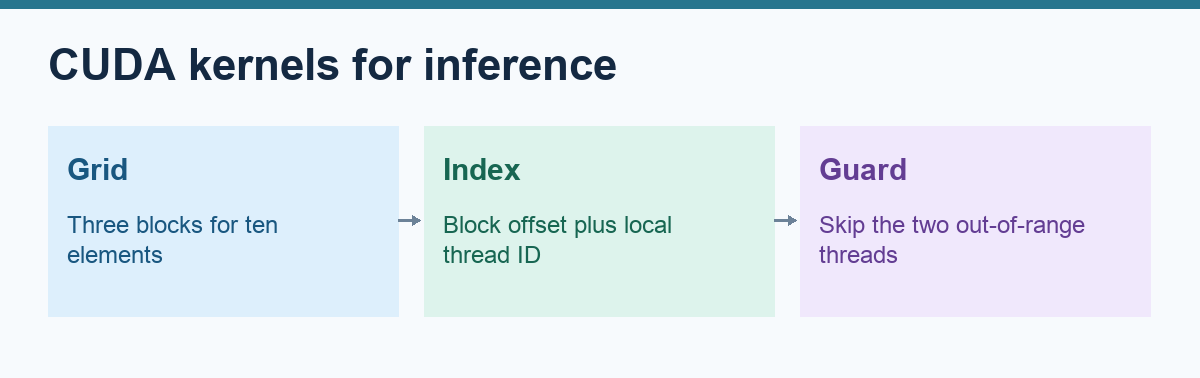

## Exercise map

| Exercise | What you will do | What to look for |
| --- | --- | --- |
| 1. Plan a launch | Return the block count using integer ceiling division. A zero-length input requires no blocks. | The tail uses a partially active block, which is why the guard matters. |
| 2. Trace the kernel | For each block and local thread, compute its global index. Keep only valid indices and apply ReLU. Return the indices and outputs in order. | Matching the reference checks both the indexing and the mathematical operation. |

In [ ]:
inputs = [-3, 1, 0, 2, -5, 6, 7, -8, 9, -10]
reference = [max(0, value) for value in inputs]

## Exercise 1. Plan a launch

Return the block count using integer ceiling division. A zero-length input requires no blocks.

In [ ]:
def blocks_for(length, threads):
    return None

In [ ]:
blocks = blocks_for(len(inputs), 4)
if blocks is None:
    print("Complete blocks_for.")
else:
    assert blocks == 3 and blocks_for(0, 4) == 0 and blocks_for(8, 4) == 2
    print("PASS — blocks:", blocks, "logical threads:", blocks * 4)

### Read the result

The tail uses a partially active block, which is why the guard matters.

## Exercise 2. Trace the kernel

For each block and local thread, compute its global index. Keep only valid indices and apply ReLU. Return the indices and outputs in order.

In [ ]:
def relu_launch(values, threads):
    return None

In [ ]:
if blocks is not None:
    result = relu_launch(inputs, 4)
    if result is not None:
        indices, output = result
        assert indices == list(range(len(inputs))) and output == reference
        assert relu_launch([], 4) == ([], [])
        print("PASS — every valid element is written once:", output)

### Read the result

Matching the reference checks both the indexing and the mathematical operation.

## Optional extension

On a machine with an NVIDIA GPU, a compatible CUDA toolkit, and `nvcc`, set `run_cuda = True` in the optional cell. The example uses managed memory and synchronizes before checking the result. This path is outside the CPU exercise.

In [ ]:
from pathlib import Path
from tempfile import TemporaryDirectory
import subprocess

run_cuda = False
if run_cuda:
    source = r"""
#include <cuda_runtime.h>
#include <cstdio>
#include <cstdlib>

void check(cudaError_t status) {
    if (status != cudaSuccess) {
        std::fprintf(stderr, "%s\n", cudaGetErrorString(status));
        std::exit(1);
    }
}

__global__ void relu(float* x, int length) {
    const int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i < length) x[i] = x[i] > 0 ? x[i] : 0;
}

int main() {
    constexpr int length = 10;
    constexpr int threads = 4;
    float* x = nullptr;
    check(cudaMallocManaged(&x, length * sizeof(float)));
    for (int i = 0; i < length; ++i) x[i] = float(i - 5);
    relu<<<(length + threads - 1) / threads, threads>>>(x, length);
    check(cudaGetLastError());
    check(cudaDeviceSynchronize());
    for (int i = 0; i < length; ++i) {
        const float expected = i > 5 ? float(i - 5) : 0.0f;
        if (x[i] != expected) return 1;
    }
    check(cudaFree(x));
    std::puts("CUDA output matches the reference");
}
"""
    with TemporaryDirectory() as directory:
        path = Path(directory)
        (path / "relu.cu").write_text(source)
        subprocess.run(["nvcc", "relu.cu", "-o", "relu"], cwd=path, check=True)
        subprocess.run([str(path / "relu")], check=True)

## Reading

Philip Kiely, *Inference Engineering*, §§4.1–4.1.1, pp. 96–98.

- [NVIDIA CUDA programming guide](https://docs.nvidia.com/cuda/cuda-programming-guide/02-basics/writing-cuda-kernels.html)
- [NVIDIA cuBLAS documentation](https://docs.nvidia.com/cuda/cublas/)